# The bootstrap: Monte Carlo on data

*Beyond the scriptum — an application.*

---

All the other notebooks simulate a **model** that we specified ourselves: we know the distribution, we
generate from it, we compute the expectation. The bootstrap does something different.

You have **measured data** and you compute some statistic from it — a mean, a median, a correlation, a
ratio of quantiles. The question is: *how accurate is that number?* For the mean there is the formula
$\hat\sigma/\sqrt n$. For the median? For a ratio of two quantiles? For a correlation? The formulas
either do not exist or hold only asymptotically and under assumptions that nobody checks.

The **bootstrap** (Efron, 1979) answers without formulas. The idea is brazenly simple:

> We do not know the true distribution, but we have a sample. So **let us pretend the sample IS the
> distribution**, and draw from it.

Concretely: from $n$ measured values we draw $n$ values **with replacement**, compute the statistic,
and repeat a thousand times. The variance of those thousands of values estimates the variance of the
original.

You will see:

- a bootstrap interval for the mean, compared with the classical formula
- the median and a correlation, where there is no formula
- **a coverage experiment** — does the bootstrap deliver what it promises?
- and where it fails (because it does fail)

In [1]:
import math
import random

import matplotlib.pyplot as plt

random.seed(1)  # reproducible results


def mean(d):
    return sum(d) / len(d)


def median(d):
    s = sorted(d)
    n = len(s)
    return s[n // 2] if n % 2 else (s[n // 2 - 1] + s[n // 2]) / 2


def std_dev(d):
    m = mean(d)
    return math.sqrt(sum((x - m) ** 2 for x in d) / (len(d) - 1))


def bootstrap(data, statistic, B=4000):
    '''B bootstrap replications of the statistic.'''
    n = len(data)
    return [statistic([data[random.randrange(n)] for _ in range(n)]) for _ in range(B)]


def interval(replications, alpha=0.05):
    '''The percentile confidence interval.'''
    s = sorted(replications)
    B = len(s)
    return s[int(alpha / 2 * B)], s[int((1 - alpha / 2) * B)]


# the "measured" data: server response times in ms — skewed, as waiting times tend to be
TRUE_LOG_CENTRE, TRUE_LOG_SD = 1.0, 0.6
TRUE_MEAN = math.exp(TRUE_LOG_CENTRE + TRUE_LOG_SD**2 / 2)
TRUE_MEDIAN = math.exp(TRUE_LOG_CENTRE)


def new_measurements(n):
    return [math.exp(random.gauss(TRUE_LOG_CENTRE, TRUE_LOG_SD)) for _ in range(n)]


data = new_measurements(40)
print(f"measured {len(data)} values, the first eight: {[round(x, 2) for x in data[:8]]}")
print(f"sample mean {mean(data):.4f}, median {median(data):.4f}")
print(f"\n(for a check — we made the data from a lognormal distribution,")
print(f" so the true mean is {TRUE_MEAN:.4f} and the median {TRUE_MEDIAN:.4f};")
print(f" in practice we would of course not know that)")

measured 40 values, the first eight: [5.89, 6.49, 2.83, 1.72, 1.41, 2.77, 1.47, 1.15]
sample mean 3.2998, median 3.0037

(for a check — we made the data from a lognormal distribution,
 so the true mean is 3.2544 and the median 2.7183;
 in practice we would of course not know that)


## 1. An interval for the mean: a comparison with the formula

We start where we **do have** a formula, so that we can trust the bootstrap elsewhere. The classical
interval for the expectation is

$$\bar x \pm 1.96\,\frac{\hat\sigma}{\sqrt n}.$$

The bootstrap gets to the same number by a completely different route — by drawing from its own
data.

                  method                   interval    width
         classical (CLT) [    2.7218,     3.8779]   1.1561
               bootstrap [    2.7858,     3.9281]   1.1423

bootstrap standard error: 0.2916
classical sigma/sqrt(n):  0.2949


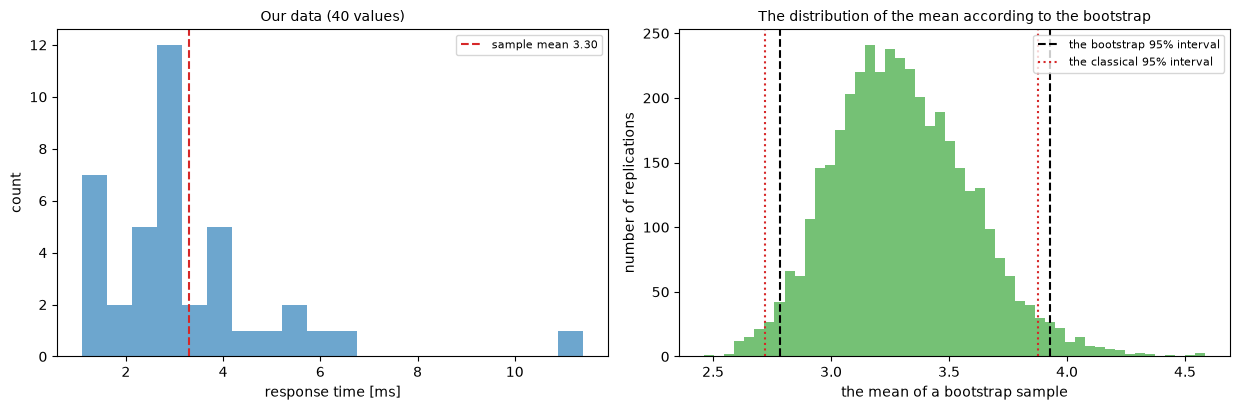

In [2]:
rep_mean = bootstrap(data, mean)
lo_b, hi_b = interval(rep_mean)

m = mean(data)
half = 1.96 * std_dev(data) / math.sqrt(len(data))
print(f"{'method':>24s} {'interval':>26s} {'width':>8s}")
print(f"{'classical (CLT)':>24s} [{m - half:>10.4f}, {m + half:>10.4f}] {2 * half:>8.4f}")
print(f"{'bootstrap':>24s} [{lo_b:>10.4f}, {hi_b:>10.4f}] {hi_b - lo_b:>8.4f}")
print(f"\nbootstrap standard error: {std_dev(rep_mean):.4f}")
print(f"classical sigma/sqrt(n):  {std_dev(data) / math.sqrt(len(data)):.4f}")

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2))
ax = axes[0]
ax.hist(data, bins=20, alpha=0.65, color="tab:blue")
ax.axvline(m, color="tab:red", ls="--", label=f"sample mean {m:.2f}")
ax.set_xlabel("response time [ms]")
ax.set_ylabel("count")
ax.set_title(f"Our data ({len(data)} values)", fontsize=10)
ax.legend(fontsize=8)

ax = axes[1]
ax.hist(rep_mean, bins=50, alpha=0.65, color="tab:green")
ax.axvline(lo_b, color="k", ls="--")
ax.axvline(hi_b, color="k", ls="--", label="the bootstrap 95% interval")
ax.axvline(m - half, color="tab:red", ls=":")
ax.axvline(m + half, color="tab:red", ls=":", label="the classical 95% interval")
ax.set_xlabel("the mean of a bootstrap sample")
ax.set_ylabel("number of replications")
ax.set_title("The distribution of the mean according to the bootstrap", fontsize=10)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

Both intervals come out practically the same — which is exactly what we want to see. The bootstrap
produced nothing new where a formula works; it merely confirmed it, without knowing it.

Now the more interesting part.

## 2. Where there is no formula

**The median.** An asymptotic formula exists, but it needs an estimate of the density at the median —
which is a problem in itself. The bootstrap needs nothing.

**A correlation, ratios of quantiles, the difference of the medians of two groups.** There the
formulas either do not exist or are so inconvenient that nobody uses them.

The bootstrap treats them exactly like the mean — **a single function changes**.

In [3]:
def quantile_ratio(d):
    '''The 95th percentile divided by the median — a measure of "how bad the tail is".'''
    s = sorted(d)
    return s[int(0.95 * len(s))] / median(s)


print(f"{'statistic':>24s} {'value':>10s} {'95% interval (bootstrap)':>28s}")
for name, stat in (("mean", mean),
                   ("median", median),
                   ("standard deviation", std_dev),
                   ("95th percentile / median", quantile_ratio)):
    rep = bootstrap(data, stat)
    lo, hi = interval(rep)
    print(f"{name:>24s} {stat(data):>10.4f} [{lo:>11.4f}, {hi:>11.4f}]")

print("\nAll four rows were produced by the same code — only the function passed in differed.")
print("That is the main thing about the bootstrap: it needs no new theory for every statistic.")

               statistic      value     95% interval (bootstrap)
                    mean     3.2998 [     2.7717,      3.9143]


                  median     3.0037 [     2.6810,      3.1968]
      standard deviation     1.8652 [     1.0829,      2.6404]
95th percentile / median     2.1594 [     1.7030,      4.0296]

All four rows were produced by the same code — only the function passed in differed.
That is the main thing about the bootstrap: it needs no new theory for every statistic.


## 3. Does the bootstrap deliver what it promises?

The interval is called 95 %, so it should cover the true value in 95 % of cases. We check that the
same way as for the insurance company in exercise 9: we generate many **new** data sets, compute an
interval for each one, and measure how often it hits.

We can afford it here, because we made the data ourselves and know the true value.

In [4]:
def coverage(n, stat, true_value, repeats=400, B=600):
    hits_boot = 0
    hits_clt = 0
    for _ in range(repeats):
        d = new_measurements(n)
        lo, hi = interval(bootstrap(d, stat, B))
        hits_boot += lo <= true_value <= hi
        if stat is mean:
            m_, p_ = mean(d), 1.96 * std_dev(d) / math.sqrt(n)
            hits_clt += m_ - p_ <= true_value <= m_ + p_
    return hits_boot / repeats, (hits_clt / repeats if stat is mean else None)


print(f"{'n':>5s} {'statistic':>10s} {'bootstrap coverage':>20s} {'CLT coverage':>14s}")
for n in (20, 40, 100, 400):
    pb, pc = coverage(n, mean, TRUE_MEAN)
    print(f"{n:>5d} {'mean':>10s} {pb:>20.3f} {pc:>14.3f}")
    pb, _ = coverage(n, median, TRUE_MEDIAN)
    print(f"{n:>5d} {'median':>10s} {pb:>20.3f} {'—':>14s}")

print("\nFor small n both methods promise more than they deliver (around 90 % instead of 95 %) — the data")
print("are skewed and forty values are not enough. As n grows both approach 95 %.")
print("So the bootstrap is NOT magic: it inherits the same weakness as the classical formula.")

    n  statistic   bootstrap coverage   CLT coverage


   20       mean                0.907          0.905


   20     median                0.927              —


   40       mean                0.915          0.927


   40     median                0.938              —


  100       mean                0.943          0.943


  100     median                0.953              —


  400       mean                0.940          0.945


  400     median                0.935              —

For small n both methods promise more than they deliver (around 90 % instead of 95 %) — the data
are skewed and forty values are not enough. As n grows both approach 95 %.
So the bootstrap is NOT magic: it inherits the same weakness as the classical formula.


This is more important than the method itself. The bootstrap is often sold as a solution that always
works — and the experiment shows that **for small skewed samples it promises a precision it does not
have**, exactly like the classical formula. It does not supply information that is not in the data.

## 4. Where the bootstrap really fails

One case is worth showing because it is so vivid: **the maximum**.

A bootstrap sample is drawn from the measured values, so it can never contain anything larger than the
observed maximum. The distribution of the bootstrapped maximum is therefore truncated from above — and
an interval for the true maximum is systematically wrong.

the observed maximum: 18.2967
bootstrap replications of the maximum: 9 distinct values out of 4000 replications
the fraction of replications equal to the observed maximum: 63.2%


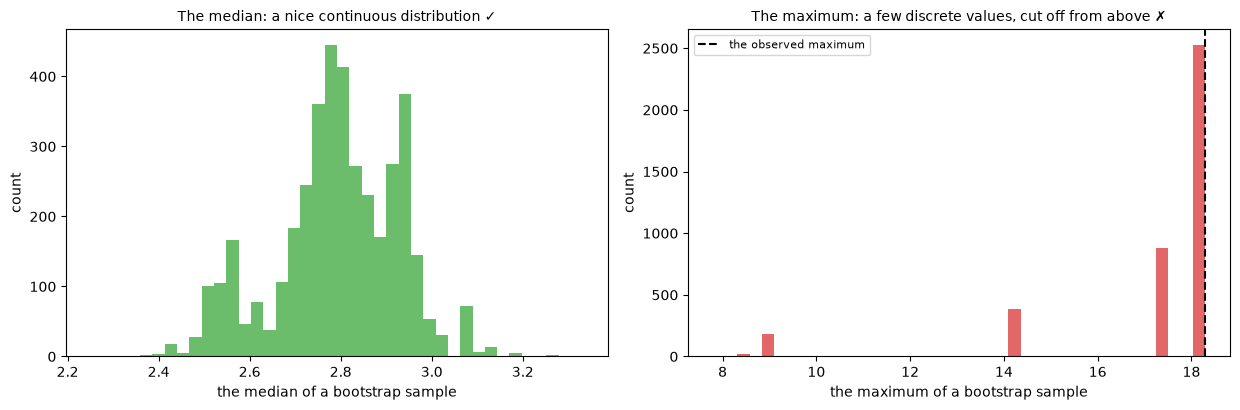


The bootstrap works for statistics that change SMOOTHLY with the distribution of the data
(the mean, the median, interior quantiles, a correlation). For those that depend on
the very edge (the maximum, the minimum, the support) it fails — and no number of
replications will fix it, because the information about the tail is simply not in the data.


In [5]:
data_large = new_measurements(200)

rep_max = bootstrap(data_large, max, 4000)
print(f"the observed maximum: {max(data_large):.4f}")
print(f"bootstrap replications of the maximum: {len(set(rep_max))} distinct values out of 4000 replications")
print(f"the fraction of replications equal to the observed maximum: "
      f"{sum(1 for v in rep_max if v == max(data_large)) / len(rep_max):.1%}")

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2))
ax = axes[0]
ax.hist(bootstrap(data_large, median, 4000), bins=40, alpha=0.7, color="tab:green")
ax.set_xlabel("the median of a bootstrap sample")
ax.set_ylabel("count")
ax.set_title("The median: a nice continuous distribution ✓", fontsize=10)

ax = axes[1]
ax.hist(rep_max, bins=40, alpha=0.7, color="tab:red")
ax.axvline(max(data_large), color="k", ls="--", label="the observed maximum")
ax.set_xlabel("the maximum of a bootstrap sample")
ax.set_ylabel("count")
ax.set_title("The maximum: a few discrete values, cut off from above ✗", fontsize=10)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

print("\nThe bootstrap works for statistics that change SMOOTHLY with the distribution of the data")
print("(the mean, the median, interior quantiles, a correlation). For those that depend on")
print("the very edge (the maximum, the minimum, the support) it fails — and no number of")
print("replications will fix it, because the information about the tail is simply not in the data.")

## Summary

| Concept | What to remember |
|---------|------------------|
| The idea | pretend the sample **is** the distribution, and draw from it with replacement |
| What it can do | an interval for any statistic without deriving a formula |
| The check | for the mean it gives practically the same as the classical $\hat\sigma/\sqrt n$ |
| Universality | **a single function** changes: the median, a correlation, a ratio of quantiles… |
| The coverage | for small skewed samples around 90 %, not 95 % — just like the formula |
| Where it fails | statistics that depend on the edge (the maximum, the minimum) — a sample cannot reach further than the data did |
| How it differs from the rest | it simulates from the **data**, not from a model we specified |

The main idea: the bootstrap does not supply information the data do not contain. It only extracts the
information that is there, without having to derive a formula for each statistic separately.

### Try it yourself

1. Compute a bootstrap interval for **the difference of the medians** of two groups and compare it
   with a classical t-test on the means. When do the conclusions differ?
2. Try the **bias**: the bootstrap estimate of the bias is $\overline{\theta^*} - \hat\theta$. Is the
   standard deviation biased? By how much?
3. Run the coverage experiment for `quantile_ratio`. Does the interval hold better or worse than for
   the median?
4. Instead of the percentile interval try **BCa**, or at least the "basic" interval
   $[2\hat\theta - q_{0.975},\ 2\hat\theta - q_{0.025}]$. Does the coverage improve for the skewed
   data?
5. For $n = 5$ compute how many distinct bootstrap samples there even are. What does that say about
   the usability of the method for very small data?
6. Replace the lognormal data by normal ones and repeat the coverage experiment. Does that confirm
   that the skew is the problem, and not the bootstrap itself?